Try relative data abundance x imbalance x active and inactive chem space distribution

In [1]:
import re
import pandas as pd

with open(r"Q:\Abteilungsprojekte\uchem\Projekte\Aktuelle Projekte\1179_MLinvitroTox\MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\final_models\log\modelfitting.log") as f:
    text = f.read()

pattern = re.compile(
    r"Included AEID:\s*(\d+).*?"
    r"Binarized Label Count TOTAL:\s*(\d+)\s*datapoints with\s*(\d+)\s*inactive,\s*(\d+)\s*active\s*\(([\d.]+)%",
    re.S
)

data = pattern.findall(text)

df = pd.DataFrame(data, columns=[
    "aeid",
    "total",
    "inactive",
    "active",
    "percent_active"
])

df = df.astype({
    "aeid": int,
    "total": int,
    "inactive": int,
    "active": int,
    "percent_active": float
})

In [2]:
df[['total_rel', 'percent_active_rel']] = (
    df[['total', 'percent_active']]
    .div(df[['total', 'percent_active']].sum())
)

In [3]:
df.head(3)

,aeid,total,inactive,active,percent_active,total_rel,percent_active_rel
0,100,1492,1398,94,6.30,0.004767,0.001220
1,1002,423,351,72,17.02,0.001351,0.003296
2,1004,417,351,66,15.83,0.001332,0.003066


In [4]:
from pathlib import Path 
import os
import numpy as np
selected_aeid = pd.read_csv(r"Q:\Abteilungsprojekte\uchem\Projekte\Aktuelle Projekte\1179_MLinvitroTox\MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\final_models\selected_aeids.csv")
base_path = Path(r'Q:\Abteilungsprojekte\uchem\Projekte\Aktuelle Projekte\1179_MLinvitroTox\MLinvitroTox_PosNeg\mlinvitrotox\data\input\invitro\pytcpl')

aeids = selected_aeid['aeid']

results = []

for aeid in aeids: 
    
    aeid_path = os.path.join(base_path, f"{aeid}.parquet.gzip") 
    df = pd.read_parquet(aeid_path) 
    df = df[['dsstox_substance_id', 'hitcall_c', 'omit_flag']].copy()
    df['aeid'] = aeid  # add aeid so we can track source
    
    results.append(df)

# Combine all into a single DataFrame
final_df = pd.concat(results, ignore_index=True)

# Optionally rename columns
final_df.rename(columns={
    'dsstox_substance_id': 'dtxsid',
    'hitcall_c': 'hitcall'
}, inplace=True)

final_df = final_df.dropna(subset=['hitcall'])
keep_compound = final_df["omit_flag"].isin(["None", np.nan])
final_df = final_df[keep_compound]
final_df['hitcall'] = (final_df['hitcall'] >= 0.9).astype(int)

In [7]:
final_df.head()

,dtxsid,hitcall,omit_flag,aeid
0,DTXSID0020022,0,None,26
1,DTXSID0020105,0,None,26
3,DTXSID0020311,0,None,26
6,DTXSID0020442,0,None,26
7,DTXSID0020446,0,None,26


In [7]:
class_assign = pd.read_csv(r"Q:\Abteilungsprojekte\uchem\Projekte\Aktuelle Projekte\1179_MLinvitroTox\MLinvitroTox_PosNeg\metrics\class_reassigned_tsne.csv")
class_assign.head(3)

,TSNE1,TSNE2,dtxsid,Superclass,Class,Subclass,Class_Reassigned,Class_Merged
0,71.85912,-44.502304,DTXSID00190950,Organohalogen compounds,Halohydrins,Fluorohydrins,Halohydrins,Organic oxides
1,62.01365,-52.841595,DTXSID00192353,Organic acids and derivatives,Organic sulfonic acids and derivatives,Organosulfonic acids and derivatives,Organic sulfonic acids and derivatives,Organometalloid compounds
2,75.81217,-37.432358,DTXSID00194615,Organic acids and derivatives,Carboxylic acids and derivatives,Acrylic acids and derivatives,Carboxylic acids and derivatives,Epoxides


In [10]:
class_assign = pd.read_csv(r"Q:\Abteilungsprojekte\uchem\Projekte\Aktuelle Projekte\1179_MLinvitroTox\MLinvitroTox_PosNeg\metrics\tsne_BA_train_coverage.csv")
class_assign.head(3)

,aeid,n_train,n_test,kde_overlap,train_space_covered_by_test,fraction_test_inside_train_hull,relative_overlap_rank,f1_micro,f1_macro,balanced_accuracy,n_pos,precision,Sensitivity,Specificity
0,26,474,175,0.820682,0.329317,0.977143,0.806667,0.62353,0.58128,0.62715,41.0,0.34667,0.63415,0.62016
1,46,455,160,0.767310,0.286853,0.975000,0.413333,0.62179,0.59925,0.59896,60.0,0.50847,0.50000,0.69792
2,63,1522,557,0.743883,0.529268,0.985637,0.186667,0.54004,0.49013,0.66985,72.0,0.20539,0.84722,0.49247


In [14]:
merged_df = df.merge(class_assign, on="aeid", how="left")
merged_df.head(3)

,aeid,total,inactive,active,percent_active,total_rel,percent_active_rel,n_train,n_test,kde_overlap,train_space_covered_by_test,fraction_test_inside_train_hull,relative_overlap_rank,f1_micro,f1_macro,balanced_accuracy,n_pos,precision,Sensitivity,Specificity
0,100,1492,1398,94,6.30,0.004767,0.001220,1545.0,538.0,0.748491,0.564165,0.983271,0.25,0.61420,0.47818,0.59631,47.0,0.12981,0.57447,0.61814
1,1002,423,351,72,17.02,0.001351,0.003296,438.0,162.0,0.834203,0.290837,0.987654,0.88,0.58065,0.50673,0.53051,34.0,0.24590,0.44118,0.61983
2,1004,417,351,66,15.83,0.001332,0.003066,432.0,160.0,0.808010,0.312757,0.956250,0.64,0.57616,0.54242,0.62828,32.0,0.29487,0.71875,0.53782


In [18]:
import numpy as np

# count unique chemicals per class
class_counts = (
    merged_df
    .groupby(['aeid', 'hitcall', 'Class_Merged'])['dtxsid']
    .nunique()
    .reset_index(name='count')
)

# class proportions within each (aeid, hitcall)
class_counts['p'] = (
    class_counts['count'] /
    class_counts.groupby(['aeid', 'hitcall'])['count'].transform('sum')
)

# entropy per (aeid, hitcall)
entropy_df = (
    class_counts
    .groupby(['aeid', 'hitcall'])
    .apply(
        lambda x: pd.Series({
            'normalized_entropy':
                -(x['p'] * np.log(x['p'])).sum() / np.log(len(x))
                if len(x) > 1 else 0
        })
    )
    .reset_index()
)

print(entropy_df)

     aeid  hitcall  normalized_entropy
0      26        0            0.725937
1      26        1            0.766730
2      46        0            0.748581
3      46        1            0.691316
4      63        0            0.732709
..    ...      ...                 ...
595  2845        1            0.788885
596  2899        0            0.820685
597  2899        1            0.844793
598  3078        0            0.805643
599  3078        1            0.825104

[600 rows x 3 columns]


C:\Users\aischlen\AppData\Local\Temp\ipykernel_20196\744655489.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


In [20]:
simpson_df = (
    class_counts
    .groupby(['aeid', 'hitcall'])
    .apply(lambda x: pd.Series({
        'simpson': (x['p']**2).sum()
    }))
    .reset_index()
)
simpson_df.head(5)

C:\Users\aischlen\AppData\Local\Temp\ipykernel_20196\4073217652.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: pd.Series({


,aeid,hitcall,simpson
0,26,0,0.163264
1,26,1,0.167372
2,46,0,0.133974
3,46,1,0.221708
4,63,0,0.136771


In [21]:
entropy_wide = (
    entropy_df
    .pivot(index='aeid',
           columns='hitcall',
           values='normalized_entropy')
    .rename(columns={
        0: 'entropy_inactive',
        1: 'entropy_active'
    })
    .reset_index()
)

In [22]:
entropy_wide

hitcall,aeid,entropy_inactive,entropy_active
0,26,0.725937,0.766730
1,46,0.748581,0.691316
2,63,0.732709,0.760005
3,64,0.754122,0.672080
4,66,0.757693,0.622944
...,...,...,...
295,2833,0.816360,0.819590
296,2843,0.808617,0.791261
297,2845,0.821352,0.788885
298,2899,0.820685,0.844793


In [24]:
meta_df = df.merge(entropy_wide, on='aeid')
meta_df.head()

,aeid,total,inactive,active,percent_active,total_rel,percent_active_rel,entropy_inactive,entropy_active
0,100,1492,1398,94,6.30,0.004767,0.001220,0.748524,0.751872
1,1002,423,351,72,17.02,0.001351,0.003296,0.737114,0.656495
2,1004,417,351,66,15.83,0.001332,0.003066,0.724823,0.730307
3,1008,423,389,34,8.04,0.001351,0.001557,0.733750,0.713517
4,101,1500,1413,87,5.80,0.004792,0.001123,0.750322,0.665947


In [25]:
meta_df['distribution_score'] = (
    meta_df['total_rel']
    * meta_df['percent_active_rel']
    * meta_df['entropy_inactive']
    * meta_df['entropy_active']
)

In [ ]:
#geometric mean to avoid small numbers
meta_df['distribution_score'] = (
    meta_df[
        ['total_rel',
         'percent_active_rel',
         'entropy_inactive',
         'entropy_active']
    ]
    .prod(axis=1) ** 0.25
)

In [ ]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- Configuration ---
root_data_dir = r"Q:\Abteilungsprojekte\uchem\Projekte\Aktuelle Projekte\1179_MLinvitroTox\MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\final_models\class"

# --- Data collection ---
results = []

for aeid_folder in os.listdir(root_data_dir):
    if not aeid_folder.isdigit():
        continue

    aeid_path = os.path.join(root_data_dir, aeid_folder, "FS_RandomForest")
    if not os.path.isdir(aeid_path):
        continue

    metrics_file = os.path.join(aeid_path, 'mb_val_structure', 'metrics.csv')
    report_file = os.path.join(aeid_path, 'mb_val_structure', 'report_default.csv')

    if os.path.exists(metrics_file) and os.path.exists(report_file):
        metrics_df = pd.read_csv(metrics_file)
        report_df = pd.read_csv(report_file, index_col=0)

        if not metrics_df.empty:
            metrics = metrics_df.iloc[0]
        else:
                continue  # skip if no metrics

        if 'True' in report_df.index:
            precision_true = report_df.loc['True', 'precision']
            recall_true = report_df.loc['True', 'recall']
        else:
            precision_true = None
            recall_true = None

        if 'False' in report_df.index:
            recall_false = report_df.loc['False', 'recall']
        else:
            recall_false = None

        results.append({
            'aeid': int(aeid_folder),
            'f1_micro': metrics.get('f1_micro'), # chose metrics I am interested in
            'f1_macro': metrics.get('f1_macro'),
            'balanced_accuracy': metrics.get('balanced_accuracy'),
            'n_pos': metrics.get('n_pos'),
            #'pr_auc': metrics.get('pr_auc')
            'precision': precision_true,
            'Sensitivity': recall_true,
            'Specificity': recall_false
        })

performance_df = pd.DataFrame(results)


In [40]:
meta_df = meta_df.merge(performance_df, on='aeid')

In [37]:
entropy_df['concentration'] = (
    1 - entropy_df['normalized_entropy']
)
conc_wide = (
    entropy_df
    .pivot(index='aeid',
           columns='hitcall',
           values='concentration')
    .rename(columns={
        0: 'conc_inactive',
        1: 'conc_active'
    })
    .reset_index()
)

In [38]:
meta_df = df.merge(conc_wide, on='aeid')

In [39]:
meta_df['distribution_score'] = (
    meta_df[
        ['total_rel',
         'percent_active_rel',
         'conc_inactive',
         'conc_active']
    ]
    .prod(axis=1) ** 0.25
)

In [56]:
meta_df.sort_values("balanced_accuracy")


,aeid,total,inactive,active,percent_active,total_rel,percent_active_rel,conc_inactive,conc_active,distribution_score,f1_micro,f1_macro,balanced_accuracy,n_pos,precision,Sensitivity,Specificity,score_z,perf_z
54,1376,474,435,39,8.23,0.001514,0.001594,0.274552,0.208370,0.019277,0.62712,0.39932,0.37286,16.0,0.01923,0.06250,0.68323,-0.977302,-3.101964
136,2444,105,67,38,36.19,0.000335,0.007009,0.251129,0.331133,0.021028,0.39474,0.39094,0.40179,14.0,0.28571,0.42857,0.37500,-0.586708,-2.734330
74,168,740,698,42,5.68,0.002364,0.001100,0.252705,0.237451,0.019876,0.65038,0.41372,0.42620,11.0,0.02326,0.18182,0.67059,-0.843760,-2.424135
56,146,732,681,51,6.97,0.002339,0.001350,0.243966,0.249043,0.020928,0.75000,0.45613,0.45223,19.0,0.03846,0.10526,0.79920,-0.609144,-2.093353
86,1820,2939,2886,53,1.80,0.009390,0.000349,0.255595,0.143816,0.018625,0.90206,0.47425,0.46393,23.0,0.00000,0.00000,0.92786,-1.122824,-1.944673
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
227,764,3730,3617,113,3.03,0.011917,0.000587,0.244847,0.412898,0.028997,0.92440,0.66390,0.80461,34.0,0.25275,0.67647,0.93274,1.190844,2.384590
111,2055,2964,2923,41,1.38,0.009470,0.000267,0.260094,0.152497,0.017800,0.71913,0.48947,0.81151,22.0,0.08000,0.90909,0.71393,-1.306788,2.472274
217,747,722,675,47,6.51,0.002307,0.001261,0.270058,0.228682,0.020587,0.83083,0.65834,0.81667,20.0,0.28070,0.80000,0.83333,-0.685214,2.537845
87,1822,3482,3423,59,1.69,0.011125,0.000327,0.259117,0.449012,0.025512,0.94018,0.65824,0.82079,23.0,0.23188,0.69565,0.94592,0.413525,2.590201


In [46]:
from scipy.stats import spearmanr

corr, p = spearmanr(
    meta_df['distribution_score'],
    meta_df['balanced_accuracy']
)

print(f"Spearman rho: {corr:.3f}, p={p:.4f}")

Spearman rho: 0.318, p=0.0000


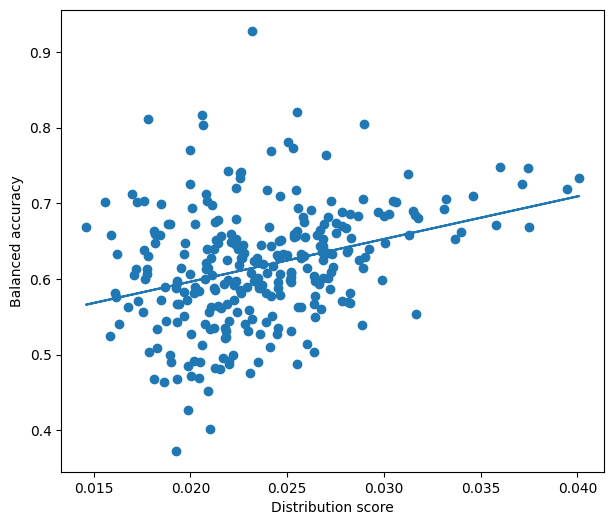

In [49]:
import numpy as np

x = meta_df['distribution_score']
y = meta_df['balanced_accuracy']

m, b = np.polyfit(x, y, 1)

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(x, y)
ax.plot(x, m*x + b)

ax.set_xlabel('Distribution score')
ax.set_ylabel('Balanced accuracy')

plt.show()

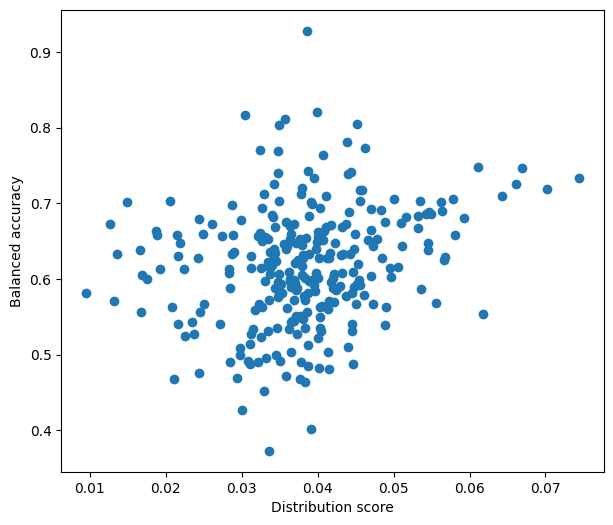

In [20]:
import numpy as np
import matplotlib.pyplot as plt

x = merged_df['distribution_score']
y = merged_df['balanced_accuracy']

#m, b = np.polyfit(x, y, 1)

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(x, y)
#ax.plot(x, m*x + b)

ax.set_xlabel('Distribution score')
ax.set_ylabel('Balanced accuracy')

plt.show()

In [50]:
rho, p = spearmanr(
    meta_df['distribution_score'],
    meta_df['balanced_accuracy']
)

print(f"Spearman rho = {rho:.2f}, p = {p:.3g}")

Spearman rho = 0.32, p = 4.86e-08


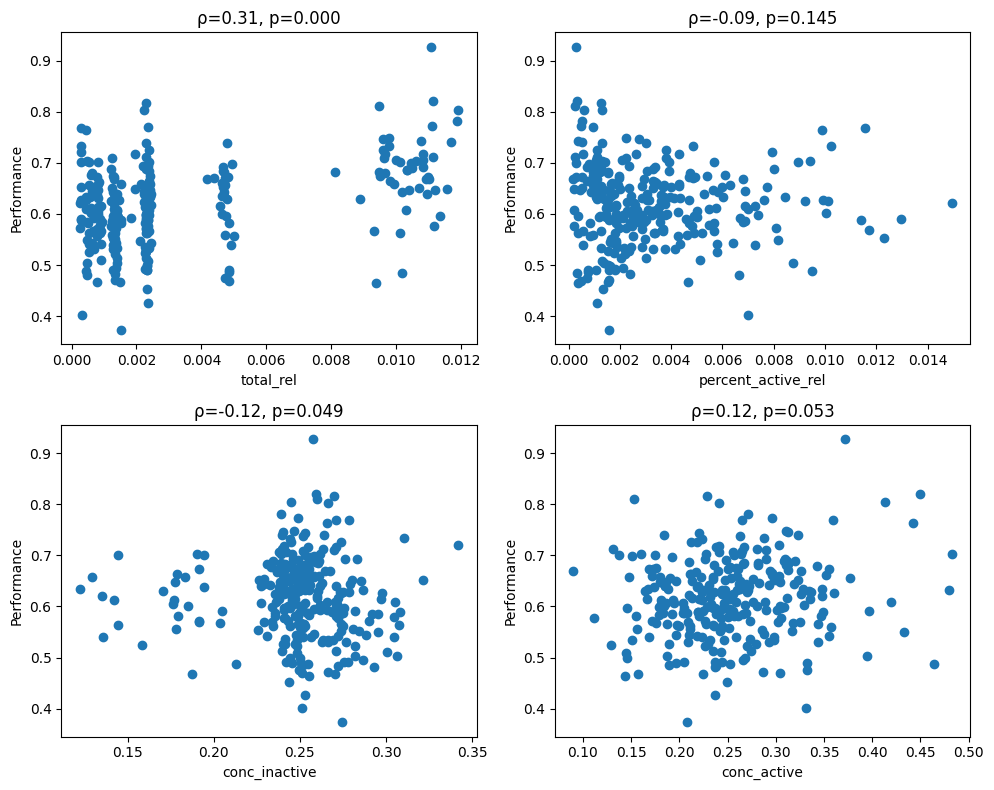

In [51]:
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

features = [
    'total_rel',
    'percent_active_rel',
    'conc_inactive',
    'conc_active'
]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, feature in zip(axes.flat, features):

    x = meta_df[feature]
    y = meta_df['balanced_accuracy']

    rho, p = spearmanr(x, y)

    ax.scatter(x, y)

    ax.set_xlabel(feature)
    ax.set_ylabel('Performance')
    ax.set_title(f'ρ={rho:.2f}, p={p:.3f}')


plt.tight_layout()
plt.show()

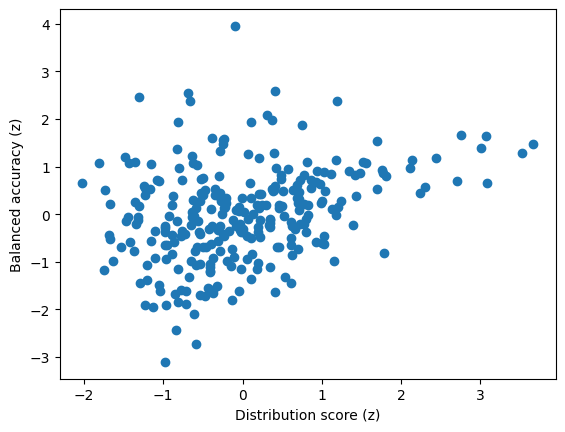

In [52]:
# standardize both varaibles (zscores)
meta_df['score_z'] = (
    meta_df['distribution_score']
    - meta_df['distribution_score'].mean()
) / meta_df['distribution_score'].std()

meta_df['perf_z'] = (
    meta_df['balanced_accuracy']
    - meta_df['balanced_accuracy'].mean()
) / meta_df['balanced_accuracy'].std()

plt.scatter(
    meta_df['score_z'],
    meta_df['perf_z']
)

plt.xlabel('Distribution score (z)')
plt.ylabel('Balanced accuracy (z)')
plt.show()

Redo the score

Data abundance: total number of chemicals / theoretical needed number of chemicals = 12683

In [48]:
import re
import pandas as pd
import numpy as np

with open(r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\final_models_retrained\log\modelfitting.log") as f:
    text = f.read()

pattern = re.compile(
    r"Included AEID:\s*(\d+).*?"
    r"Binarized Label Count TOTAL:\s*(\d+)\s*datapoints with\s*(\d+)\s*inactive,\s*(\d+)\s*active\s*\(([\d.]+)%",
    re.S
)

data = pattern.findall(text)

df = pd.DataFrame(data, columns=[
    "aeid",
    "total",
    "inactive",
    "active",
    "percent_active"
])

df = df.astype({
    "aeid": int,
    "total": int,
    "inactive": int,
    "active": int,
    "percent_active": float
})

In [2]:
dfilter = df[df['active'] >= 250]
dfilter.head(14)

,aeid,total,inactive,active,percent_active
9,103,1307,848,459,35.12
40,113,1449,1194,255,17.60
42,1134,3024,2350,674,22.29
52,134,1459,1182,277,18.99
53,135,1459,1204,255,17.48
90,1816,3057,2703,354,11.58
125,2057,3017,2670,347,11.50
131,2108,3110,2840,270,8.68
134,2127,3005,2582,423,14.08
135,2130,3058,2291,767,25.08


In [49]:
df['abundance'] = df['total'].divide(12683)

In [50]:
df['imbalance'] = np.minimum(df['percent_active'], 20) / 20

In [45]:
root_data_dir = r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\final_models_retrained\class"
selected_aeid = pd.read_csv(r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\final_models_retrained\selected_aeids.csv")
kde_overlap = pd.read_csv(r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\metrics\csv_excel_files\KDE_overlap.csv"
)
aeids = selected_aeid['aeid']

results = []

for aeid in aeids:

    try:
        features_file = os.path.join(
            root_data_dir, str(aeid),
            "FS_RandomForest", "XGBClassifier",
            "selected_features.csv"
        )

        feat_imp = os.path.join(
            root_data_dir, str(aeid),
            "FS_RandomForest", "XGBClassifier",
            "sorted_feature_importances.csv"
        )

        feats = pd.read_csv(features_file)
        imp = pd.read_csv(feat_imp)

        # assume first importance column = importance
        importance = imp.iloc[:,1].values
        importance = importance / importance.sum()

        cum_importance = np.cumsum(importance)

        # features needed to explain 100% (effectively all features)
        n_features_for_100 = np.searchsorted(cum_importance, 0.999999) + 1
        # often more useful: 75% / 99%
        n_features_for_75 = np.searchsorted(cum_importance, 0.75) + 1
        n_features_for_99 = np.searchsorted(cum_importance, 0.99) + 1

        top1 = importance[0]
        top5 = importance[:5].sum()

        # entropy = spread of importance
        entropy = -(importance * np.log(importance + 1e-12)).sum()

        results.append({
            "aeid": aeid,
            "n_features_75": n_features_for_75,
            "n_features_99": n_features_for_99,
            "n_features_100": n_features_for_100,    
            "n_features": len(feats),
            "top1_importance": top1,
            "top5_importance": top5,
            "importance_entropy": entropy,
        })

    except Exception as e:
        print(aeid, e)

summary = pd.DataFrame(results)

In [51]:
df_merged = summary.merge(kde_overlap, on="aeid", how= "left")
df_merged
df = df.merge(df_merged, on='aeid', how='left')

In [52]:
df

,aeid,total,inactive,active,percent_active,abundance,imbalance,n_features_75,n_features_99,n_features_100,n_features,top1_importance,top5_importance,importance_entropy,overlap
0,100,1492,1398,94,6.30,0.117638,0.3150,3.0,5.0,6.0,350.0,0.312467,0.991712,1.468376e+00,0.735962
1,1002,423,351,72,17.02,0.033352,0.8510,15.0,32.0,36.0,389.0,0.126195,0.433124,3.180471e+00,0.737798
2,1004,417,351,66,15.83,0.032879,0.7915,6.0,12.0,13.0,401.0,0.280722,0.721679,2.189415e+00,0.643872
3,1008,423,389,34,8.04,0.033352,0.4020,10.0,20.0,21.0,403.0,0.135670,0.510061,2.767631e+00,0.706630
4,101,1500,1413,87,5.80,0.118269,0.2900,45.0,80.0,87.0,373.0,0.051533,0.191704,4.213393e+00,0.648930
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,984,411,291,120,29.20,0.032406,1.0000,122.0,271.0,293.0,421.0,0.037043,0.102632,5.281854e+00,0.708038
296,986,414,307,107,25.85,0.032642,1.0000,5.0,10.0,10.0,391.0,0.312484,0.789695,2.017402e+00,0.680723
297,988,391,298,93,23.79,0.030829,1.0000,24.0,42.0,46.0,432.0,0.065427,0.272040,3.616461e+00,0.715119
298,990,429,382,47,10.96,0.033825,0.5480,1.0,1.0,1.0,413.0,1.000000,1.000000,-1.000089e-12,0.672219


In [53]:
df['distr'] = 1-df['overlap']

In [54]:
df['perf_score'] = (
    df[
        ['abundance',
         'imbalance',
         'distr',
         'n_features_100']
    ]
    .prod(axis=1) ** 0.25
)

In [14]:
import os
import pandas as pd

# --- Configuration ---
root_data_dir = r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\final_models_retrained\class"

# --- Data collection ---
results = []

for aeid_folder in os.listdir(root_data_dir):
    if not aeid_folder.isdigit():
        continue

    aeid_path = os.path.join(root_data_dir, aeid_folder, "FS_RandomForest")
    if not os.path.isdir(aeid_path):
        continue

    metrics_file = os.path.join(aeid_path, 'mb_val_structure', 'metrics.csv')
    report_file = os.path.join(aeid_path, 'mb_val_structure', 'report_default.csv')

    if os.path.exists(metrics_file) and os.path.exists(report_file):
        metrics_df = pd.read_csv(metrics_file)
        report_df = pd.read_csv(report_file, index_col=0)

        if not metrics_df.empty:
            metrics = metrics_df.iloc[0]
        else:
                continue  # skip if no metrics

        if 'True' in report_df.index:
            precision_true = report_df.loc['True', 'precision']
            recall_true = report_df.loc['True', 'recall']
        else:
            precision_true = None
            recall_true = None

        if 'False' in report_df.index:
            recall_false = report_df.loc['False', 'recall']
        else:
            recall_false = None

        results.append({
            'aeid': int(aeid_folder),
            'f1_micro': metrics.get('f1_micro'), # chose metrics I am interested in
            'balanced_accuracy': metrics.get('balanced_accuracy'),
            #'pr_auc': metrics.get('pr_auc')
            'precision': precision_true,
            'Sensitivity': recall_true,
            'Specificity': recall_false
        })

performance_df = pd.DataFrame(results)

In [55]:
meta_df = df.merge(performance_df, on='aeid')

In [56]:
meta_df.sort_values("balanced_accuracy")

,aeid,total,inactive,active,percent_active,abundance,imbalance,n_features_75,n_features_99,n_features_100,...,top5_importance,importance_entropy,overlap,distr,perf_score,f1_micro,balanced_accuracy,precision,Sensitivity,Specificity
136,2444,105,67,38,36.19,0.008279,1.0000,2.0,5.0,5.0,...,1.000000,0.995467,0.768915,0.231085,0.312736,0.39474,0.40179,0.28571,0.42857,0.37500
206,67,1522,1485,37,2.43,0.120003,0.1215,11.0,18.0,18.0,...,0.440934,2.782716,0.698552,0.301448,0.530351,0.56554,0.42056,0.03196,0.25926,0.58185
55,1379,465,428,37,7.96,0.036663,0.3980,4.0,7.0,9.0,...,0.969818,1.707432,0.760920,0.239080,0.420945,0.73563,0.46123,0.05882,0.12500,0.79747
56,146,732,681,51,6.97,0.057715,0.3485,54.0,96.0,109.0,...,0.140271,4.447467,0.757160,0.242840,0.854200,0.81716,0.46407,0.03125,0.05263,0.87550
86,1820,2939,2886,53,1.80,0.231728,0.0900,43.0,80.0,87.0,...,0.159288,4.237330,0.790266,0.209734,0.785420,0.86820,0.46763,0.01136,0.04348,0.89179
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
214,744,722,673,49,6.79,0.056927,0.3395,18.0,32.0,36.0,...,0.359270,3.312735,0.699052,0.300948,0.676453,0.80309,0.80827,0.32353,0.81481,0.80172
217,747,722,675,47,6.51,0.056927,0.3255,21.0,46.0,52.0,...,0.350785,3.534467,0.651889,0.348111,0.761022,0.83459,0.81870,0.28571,0.80000,0.83740
87,1822,3482,3423,59,1.69,0.274541,0.0845,7.0,22.0,29.0,...,0.713637,2.227770,0.300601,0.699399,0.828222,0.95613,0.82895,0.30189,0.69565,0.96224
227,764,3730,3617,113,3.03,0.294094,0.1515,50.0,133.0,148.0,...,0.437366,3.861411,0.348354,0.651646,1.439770,0.94641,0.83019,0.34286,0.70588,0.95450


In [19]:
from scipy.stats import spearmanr

corr, p = spearmanr(
    meta_df['perf_score'],
    meta_df['balanced_accuracy']
)

print(f"Spearman rho: {corr:.3f}, p={p:.4f}")

Spearman rho: 0.422, p=0.0000


In [74]:
corr, p = spearmanr(
    meta_df['perf_score_rank'],
    meta_df['balanced_accuracy']
)

print(f"Spearman rho: {corr:.3f}, p={p:.4f}")

Spearman rho: 0.344, p=0.0000


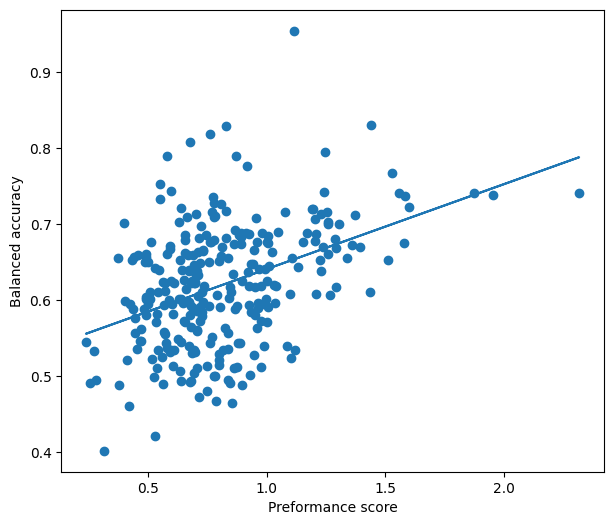

In [57]:
import numpy as np
import matplotlib.pyplot as plt

x = meta_df['perf_score']
y = meta_df['balanced_accuracy']

m, b = np.polyfit(x, y, 1)

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(x, y)
ax.plot(x, m*x + b)

ax.set_xlabel('Preformance score')
ax.set_ylabel('Balanced accuracy')

plt.show()

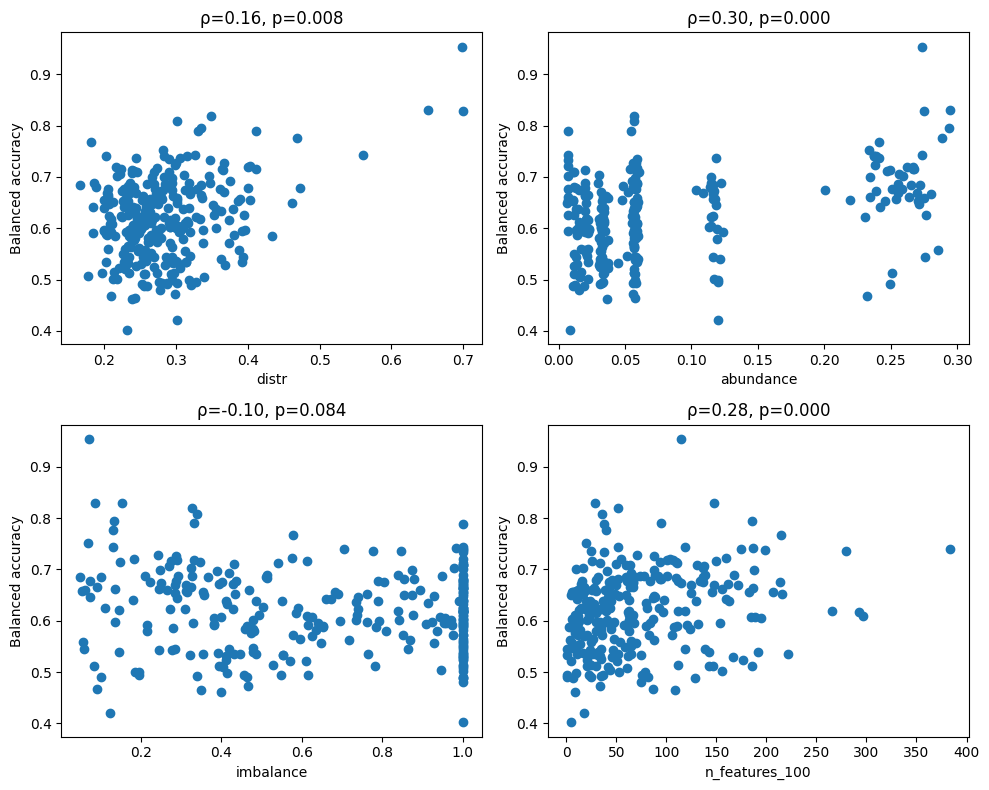

In [58]:
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

features = [
    'distr',
    'abundance',
    'imbalance',
    'n_features_100'
]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, feature in zip(axes.flat, features):

    x = meta_df[feature]
    y = meta_df['balanced_accuracy']

    rho, p = spearmanr(x, y)

    ax.scatter(x, y)

    ax.set_xlabel(feature)
    ax.set_ylabel('Balanced accuracy')
    ax.set_title(f'ρ={rho:.2f}, p={p:.3f}')


plt.tight_layout()
plt.show()

In [20]:
for col in ['abundance', 'imbalance', 'distr', 'balanced_accuracy']:
    meta_df[col + '_norm'] = (
        (meta_df[col] - meta_df[col].min()) /
        (meta_df[col].max() - meta_df[col].min())
    )

In [21]:
meta_df['perf_score_norm'] = (
    meta_df[['abundance_norm',
        'imbalance_norm',
        'distr_norm']]
    .prod(axis=1)
    .pow(1/3)
)

In [23]:
for col in ['abundance', 'imbalance', 'distr', 'balanced_accuracy']:
    meta_df[col + '_rank'] = meta_df[col].rank(pct=True)

In [24]:
meta_df['perf_score_rank'] = (
    meta_df[['abundance_rank',
        'imbalance_rank',
        'distr_rank']]
    .mean(axis=1)
)

In [90]:
df['perf_score'] = (
    df['abundance'] *
    df['imbalance'] *
    df['distr']
) ** (1/3)